# Component Label Detection: 2025 PoC Model vs. 2026 SEMAS Model

Both detectors are scored against the project ground truth (RefDes label boxes) on the
annotated PCB and schematic pages of two manuals.

| Manual | Split | Role in this notebook |
| :--- | :--- | :--- |
| Toshiba SY-330 | dev | Used while developing the 2026 pipeline |
| McIntosh MC-2100 | test | Not used to train or tune the 2026 model |

What is measured, for every page:

1. TP, FP, FN, precision, recall and F1 at two IoU thresholds: 0.5 (the project threshold,
   used for the headline tables) and 0.3 (lenient, shows boxes that are in the right place
   but loose).
2. Mean IoU of the matched boxes.
3. The effect of the input image (color scan or grayscale).
4. The effect of the inference strategy (whole page resized once, or SAHI slices).
5. Latency per page after a warm-up call.

Every table below is generated from the result rows computed in this notebook, and the rows
are written to a JSON file. No number is typed by hand.

## 1. Environment

In [2]:
import sys
import json
import time
import statistics
from pathlib import Path

# Resolve project root relative to notebook directory
current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

device = "cuda:0" if torch.cuda.is_available() else "cpu"
device_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

print("[INFO] Python executable: " + sys.executable)
print("[INFO] PyTorch version: " + str(torch.__version__))
print("[INFO] Inference device: " + device + " (" + device_name + ")")
print("[INFO] Project root: " + str(project_root))

[INFO] Python executable: /home/felixilars/Desktop/Etude_Pratique/SEMAS_local/.venv/bin/python
[INFO] PyTorch version: 2.14.0+cu130
[INFO] Inference device: cuda:0 (NVIDIA GeForce RTX 4080 Laptop GPU)
[INFO] Project root: /home/felixilars/Desktop/Etude_Pratique/SEMAS


## 2. Benchmark configuration

All settings of the comparison live in this cell. Both models receive the same confidence
threshold, image size and slicing parameters.

In [3]:
CONF_THRESHOLD = 0.20
IMAGE_SIZE = 1280
IOU_THRESHOLDS = [0.3, 0.5]
PRIMARY_IOU = 0.5
SLICE_SIZE = 1024
SLICE_OVERLAP = 0.25
SLICE_NMS_IOU = 0.40
LATENCY_REPEATS = 3
REFDES_CLASS_NAME = "compo_name"
GROUND_TRUTH_VIEWS = ["pcb", "schema"]
INPUT_MODES = ["color", "gray"]
INFERENCE_MODES = ["direct", "sliced"]

RESULTS_FILE = project_root / "results" / "model_comparison" / "detection_old_vs_new.json"

MODELS = [
    {
        "key": "old",
        "label": "Old (YOLOv8n, 2025)",
        "weights": project_root / "weights" / "best_composants.pt",
    },
    {
        "key": "new",
        "label": "New (YOLO26m, 2026)",
        "weights": project_root / "runs" / "detect" / "semas_yolo26m_exp" / "weights" / "best.pt",
    },
]

MANUALS = [
    {
        "manual_id": "Toshiba_SY_330",
        "split": "dev",
        "folder": "Toshiba-SY-330-Service-Manual",
        "pages": [5, 6],
    },
    {
        "manual_id": "McIntosh_MC_2100",
        "split": "test",
        "folder": "manualsplus_13963",
        "pages": [6, 7, 8],
    },
]

## 3. Models

The old model has one class (`compo_name`). The new model has two (`compo_name`,
`spec_value`); only its `compo_name` detections are scored, because the ground truth
contains RefDes labels only.

In [4]:
for model_spec in MODELS:
    weights_path = model_spec["weights"]
    if not weights_path.exists():
        raise FileNotFoundError("Model weights not found at: " + str(weights_path))

    detector = YOLO(str(weights_path))
    class_ids = [idx for idx, name in detector.names.items() if name == REFDES_CLASS_NAME]
    if len(class_ids) != 1:
        raise ValueError("Class " + REFDES_CLASS_NAME + " not found in " + str(weights_path))

    model_spec["detector"] = detector
    model_spec["class_id"] = class_ids[0]
    model_spec["sliced_detector"] = AutoDetectionModel.from_pretrained(
        model_type="yolov8",
        model_path=str(weights_path),
        confidence_threshold=CONF_THRESHOLD,
        device=device,
    )

    size_mb = round(weights_path.stat().st_size / 1e6, 2)
    print("[INFO] " + model_spec["label"] + ": " + weights_path.name + " (" + str(size_mb) + " MB), classes " + str(detector.names))

[INFO] Old (YOLOv8n, 2025): best_composants.pt (6.34 MB), classes {0: 'compo_name'}
[INFO] New (YOLO26m, 2026): best.pt (44.16 MB), classes {0: 'compo_name', 1: 'spec_value'}


## 4. Ground truth loading and matching

A page is scored against every ground truth box drawn on it, PCB and schematic together
(McIntosh page 8 carries both). Predictions are matched greedily in decreasing confidence
order; each ground truth box can be matched once.

In [5]:
def find_page_image(folder_name, manual_id, page_num):
    """ Locate the rendered image of one manual page.

    Args:
      - folder_name (str) : Manual folder under data/extracted_manuals.
      - manual_id (str) : Manual identifier used as the image file prefix.
      - page_num (int) : 1-based page index.
    Returns: Path to the page image.
    """
    file_name = manual_id + "_page_" + str(page_num).zfill(3) + ".png"
    manual_dir = project_root / "data" / "extracted_manuals" / folder_name
    matches = sorted(manual_dir.glob("*/" + file_name))
    if not matches:
        raise FileNotFoundError("Page image not found: " + file_name + " under " + str(manual_dir))
    return matches[0]


def load_page_ground_truth(gt_path, page_num):
    """ Load every ground truth RefDes box drawn on one page.

    Args:
      - gt_path (Path) : Path to ground truth JSON file.
      - page_num (int) : 1-based page index.
    Returns: Tuple of (list of boxes [x1, y1, x2, y2], list of views present on the page).
    """
    with open(gt_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    boxes = []
    views = []
    for view_type in GROUND_TRUTH_VIEWS:
        for item in data.get("components", {}).values():
            raw_box = item.get("bbox_" + view_type)
            if item.get("page_" + view_type) == page_num and raw_box and len(raw_box) == 4:
                boxes.append([float(x) for x in raw_box])
                if view_type not in views:
                    views.append(view_type)

    return boxes, views


def compute_iou(box1, box2):
    """ Compute Intersection over Union between two bounding boxes [x1, y1, x2, y2].

    Args:
      - box1 (list) : Bounding box coordinates [x1, y1, x2, y2].
      - box2 (list) : Bounding box coordinates [x1, y1, x2, y2].
    Returns: IoU ratio as float.
    """
    x_a = max(box1[0], box2[0])
    y_a = max(box1[1], box2[1])
    x_b = min(box1[2], box2[2])
    y_b = min(box1[3], box2[3])

    inter_w = max(0.0, x_b - x_a)
    inter_h = max(0.0, y_b - y_a)
    inter_area = inter_w * inter_h

    area1 = max(0.0, box1[2] - box1[0]) * max(0.0, box1[3] - box1[1])
    area2 = max(0.0, box2[2] - box2[0]) * max(0.0, box2[3] - box2[1])
    union_area = area1 + area2 - inter_area

    if union_area <= 0.0:
        return 0.0
    return inter_area / union_area


def detection_scores(tp, fp, fn):
    """ Derive precision, recall and F1 from match counts.

    Args:
      - tp (int) : True positives.
      - fp (int) : False positives.
      - fn (int) : False negatives.
    Returns: Tuple of (precision, recall, f1).
    """
    precision = tp / max(1, tp + fp)
    recall = tp / max(1, tp + fn)
    denom = precision + recall
    f1 = (2.0 * precision * recall) / denom if denom > 0.0 else 0.0
    return precision, recall, f1


def evaluate_detection_predictions(pred_boxes, pred_scores, gt_boxes, iou_thresh):
    """ Score predicted boxes against ground truth boxes with greedy one-to-one matching.

    Predictions are visited in decreasing confidence order. Each prediction takes the
    unmatched ground truth box with the highest IoU, if that IoU reaches the threshold.

    Args:
      - pred_boxes (list) : Predicted boxes [x1, y1, x2, y2].
      - pred_scores (list) : Confidence of each predicted box.
      - gt_boxes (list) : Ground truth boxes [x1, y1, x2, y2].
      - iou_thresh (float) : Minimum IoU for a true positive.
    Returns: Dictionary containing counts, precision, recall, f1 and mean_iou.
    """
    order = sorted(range(len(pred_boxes)), key=lambda idx: -pred_scores[idx])
    matched_gt = set()
    iou_scores = []

    for p_idx in order:
        best_iou = 0.0
        best_gt_idx = -1
        for g_idx, g_box in enumerate(gt_boxes):
            if g_idx in matched_gt:
                continue
            iou = compute_iou(pred_boxes[p_idx], g_box)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = g_idx
        if best_gt_idx != -1 and best_iou >= iou_thresh:
            matched_gt.add(best_gt_idx)
            iou_scores.append(best_iou)

    tp = len(matched_gt)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - tp
    precision, recall, f1 = detection_scores(tp, fp, fn)
    mean_iou = float(np.mean(iou_scores)) if iou_scores else 0.0

    return {
        "total_gt": len(gt_boxes),
        "total_preds": len(pred_boxes),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "f1": round(f1, 4),
        "mean_iou": round(mean_iou, 4),
    }

## 5. Inference helpers

`direct` resizes the whole page to the model input size. `sliced` runs SAHI tiles and merges
them with NMS. Latency is the median of several timed calls made after one untimed warm-up
call, so model loading and CUDA start-up are excluded.

In [6]:
def prepare_input(image_bgr, input_mode):
    """ Build the model input for one input mode.

    Args:
      - image_bgr (ndarray) : Page image in BGR channel order.
      - input_mode (str) : color or gray.
    Returns: Three-channel BGR image.
    """
    if input_mode == "gray":
        gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
        return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    return image_bgr


def predict_direct(model_spec, image_bgr):
    """ Detect RefDes labels on the whole page in one forward pass.

    Args:
      - model_spec (dict) : Entry of MODELS with a loaded detector.
      - image_bgr (ndarray) : Three-channel BGR page image.
    Returns: Tuple of (list of boxes [x1, y1, x2, y2], list of confidences).
    """
    result = model_spec["detector"].predict(image_bgr, conf=CONF_THRESHOLD, imgsz=IMAGE_SIZE, verbose=False)[0]
    boxes = []
    scores = []
    for det in result.boxes:
        if int(det.cls[0]) == model_spec["class_id"]:
            boxes.append(det.xyxy[0].cpu().numpy().tolist())
            scores.append(float(det.conf[0]))
    return boxes, scores


def predict_sliced(model_spec, image_bgr):
    """ Detect RefDes labels with SAHI sliced inference.

    Args:
      - model_spec (dict) : Entry of MODELS with a loaded SAHI detector.
      - image_bgr (ndarray) : Three-channel BGR page image.
    Returns: Tuple of (list of boxes [x1, y1, x2, y2], list of confidences).
    """
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    sliced = get_sliced_prediction(
        image_rgb,
        model_spec["sliced_detector"],
        slice_height=SLICE_SIZE,
        slice_width=SLICE_SIZE,
        overlap_height_ratio=SLICE_OVERLAP,
        overlap_width_ratio=SLICE_OVERLAP,
        postprocess_type="NMS",
        postprocess_match_metric="IOU",
        postprocess_match_threshold=SLICE_NMS_IOU,
        verbose=0,
    )
    boxes = []
    scores = []
    for obj in sliced.object_prediction_list:
        if obj.category.id == model_spec["class_id"]:
            b = obj.bbox
            boxes.append([float(b.minx), float(b.miny), float(b.maxx), float(b.maxy)])
            scores.append(float(obj.score.value))
    return boxes, scores


PREDICTORS = {"direct": predict_direct, "sliced": predict_sliced}


def timed_prediction(predict_fn, model_spec, image_bgr):
    """ Run a predictor once untimed, then time repeated calls.

    Args:
      - predict_fn (callable) : predict_direct or predict_sliced.
      - model_spec (dict) : Entry of MODELS.
      - image_bgr (ndarray) : Three-channel BGR page image.
    Returns: Tuple of (boxes, scores, median latency in milliseconds).
    """
    boxes, scores = predict_fn(model_spec, image_bgr)
    durations = []
    for _ in range(LATENCY_REPEATS):
        t0 = time.perf_counter()
        boxes, scores = predict_fn(model_spec, image_bgr)
        durations.append((time.perf_counter() - t0) * 1000.0)
    return boxes, scores, statistics.median(durations)

## 6. Run the benchmark

Every combination of page, input mode, model and inference strategy is run. One result row
is stored per IoU threshold.

In [7]:
benchmark_rows = []
predictions = {}
page_index = []

for manual in MANUALS:
    gt_file = project_root / "data" / "ground_truth" / (manual["manual_id"] + ".json")
    for page_num in manual["pages"]:
        img_file = find_page_image(manual["folder"], manual["manual_id"], page_num)
        gt_boxes, views = load_page_ground_truth(gt_file, page_num)
        image_bgr = cv2.imread(str(img_file))
        if image_bgr is None:
            raise ValueError("Unreadable page image: " + str(img_file))
        if not gt_boxes:
            raise ValueError("No ground truth box on " + manual["manual_id"] + " page " + str(page_num))

        page_index.append({"manual_id": manual["manual_id"], "page": page_num, "img_file": img_file, "gt_boxes": gt_boxes})
        print("[INFO] " + manual["manual_id"] + " page " + str(page_num) + " (" + "+".join(views) + "): " + str(len(gt_boxes)) + " ground truth labels, image " + str(image_bgr.shape[1]) + "x" + str(image_bgr.shape[0]))

        for input_mode in INPUT_MODES:
            model_input = prepare_input(image_bgr, input_mode)
            for model_spec in MODELS:
                for inference_mode in INFERENCE_MODES:
                    boxes, scores, latency_ms = timed_prediction(PREDICTORS[inference_mode], model_spec, model_input)
                    predictions[(manual["manual_id"], page_num, input_mode, model_spec["key"], inference_mode)] = (boxes, scores)
                    for iou_thresh in IOU_THRESHOLDS:
                        row = evaluate_detection_predictions(boxes, scores, gt_boxes, iou_thresh)
                        row["manual_id"] = manual["manual_id"]
                        row["split"] = manual["split"]
                        row["page"] = page_num
                        row["views"] = "+".join(views)
                        row["model"] = model_spec["key"]
                        row["input"] = input_mode
                        row["inference"] = inference_mode
                        row["iou_thresh"] = iou_thresh
                        row["latency_ms"] = round(latency_ms, 1)
                        benchmark_rows.append(row)

print("[RESULT] " + str(len(benchmark_rows)) + " result rows computed")

[INFO] Toshiba_SY_330 page 5 (schema): 128 ground truth labels, image 4961x3508
[INFO] Toshiba_SY_330 page 6 (pcb): 146 ground truth labels, image 4961x3508
[INFO] McIntosh_MC_2100 page 6 (pcb): 74 ground truth labels, image 2197x2959
[INFO] McIntosh_MC_2100 page 7 (schema): 66 ground truth labels, image 2255x2958
[INFO] McIntosh_MC_2100 page 8 (pcb+schema): 73 ground truth labels, image 2194x2958
[RESULT] 80 result rows computed


In [8]:
RESULTS_FILE.parent.mkdir(parents=True, exist_ok=True)
payload = {
    "config": {
        "conf_threshold": CONF_THRESHOLD,
        "image_size": IMAGE_SIZE,
        "iou_thresholds": IOU_THRESHOLDS,
        "slice_size": SLICE_SIZE,
        "slice_overlap": SLICE_OVERLAP,
        "slice_nms_iou": SLICE_NMS_IOU,
        "latency_repeats": LATENCY_REPEATS,
        "device": device_name,
        "torch_version": str(torch.__version__),
        "models": {spec["key"]: str(spec["weights"].relative_to(project_root)) for spec in MODELS},
    },
    "rows": benchmark_rows,
}
with open(RESULTS_FILE, "w", encoding="utf-8") as f:
    json.dump(payload, f, indent=2)
print("[INFO] Results written to " + str(RESULTS_FILE.relative_to(project_root)))

[INFO] Results written to results/model_comparison/detection_old_vs_new.json


## 7. Result tables

Helpers that filter the result rows, pool them per manual (TP, FP and FN are summed over the
pages of the manual before computing precision, recall and F1) and render Markdown tables.

In [9]:
MODEL_LABELS = {spec["key"]: spec["label"] for spec in MODELS}


def select_rows(rows, model, input_mode, inference_mode, iou_thresh):
    """ Filter result rows by run settings.

    Args:
      - rows (list) : Result rows.
      - model (str) : Model key.
      - input_mode (str) : color or gray.
      - inference_mode (str) : direct or sliced.
      - iou_thresh (float) : IoU threshold of the rows.
    Returns: List of matching rows.
    """
    return [
        r for r in rows
        if r["model"] == model and r["input"] == input_mode
        and r["inference"] == inference_mode and r["iou_thresh"] == iou_thresh
    ]


def pool_rows(rows):
    """ Pool page-level rows into one set of metrics.

    Args:
      - rows (list) : Result rows of the pages to pool.
    Returns: Dictionary with summed counts and derived metrics.
    """
    tp = sum(r["tp"] for r in rows)
    fp = sum(r["fp"] for r in rows)
    fn = sum(r["fn"] for r in rows)
    precision, recall, f1 = detection_scores(tp, fp, fn)
    mean_iou = sum(r["mean_iou"] * r["tp"] for r in rows) / max(1, tp)
    return {
        "total_gt": tp + fn,
        "total_preds": tp + fp,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mean_iou": mean_iou,
    }


def percent(value):
    """ Format a ratio as a percentage string.

    Args:
      - value (float) : Ratio between 0 and 1.
    Returns: Percentage with one decimal.
    """
    return str(round(value * 100.0, 1)) + "%"


def metric_cells(metrics):
    """ Format one set of metrics as table cells.

    Args:
      - metrics (dict) : Output of pool_rows or a result row.
    Returns: List of cell strings.
    """
    return [
        str(metrics["total_gt"]), str(metrics["total_preds"]),
        str(metrics["tp"]), str(metrics["fp"]), str(metrics["fn"]),
        percent(metrics["precision"]), percent(metrics["recall"]), percent(metrics["f1"]),
        str(round(metrics["mean_iou"], 3)),
    ]


METRIC_HEADERS = ["GT", "Preds", "TP", "FP", "FN", "Precision", "Recall", "F1", "Mean IoU"]


def show_table(headers, table_rows):
    """ Render a Markdown table in the notebook.

    Args:
      - headers (list) : Column titles.
      - table_rows (list) : List of rows, each a list of cell strings.
    Returns: None.
    """
    lines = ["| " + " | ".join(headers) + " |", "|" + " --- |" * len(headers)]
    for cells in table_rows:
        lines.append("| " + " | ".join(cells) + " |")
    display(Markdown("\n".join(lines)))


def manual_table(variants, variant_header):
    """ Show metrics pooled per manual for a list of run variants.

    Args:
      - variants (list) : Tuples of (variant label, input mode, inference mode, IoU threshold).
      - variant_header (str) : Title of the variant column.
    Returns: None.
    """
    table_rows = []
    for manual in MANUALS:
        for label, input_mode, inference_mode, iou_thresh in variants:
            for spec in MODELS:
                rows = select_rows(benchmark_rows, spec["key"], input_mode, inference_mode, iou_thresh)
                rows = [r for r in rows if r["manual_id"] == manual["manual_id"]]
                cells = [manual["manual_id"] + " (" + manual["split"] + ")", label, spec["label"]]
                table_rows.append(cells + metric_cells(pool_rows(rows)))
    show_table(["Manual", variant_header, "Model"] + METRIC_HEADERS, table_rows)

### 7.1 Headline: both models, same setting, two IoU thresholds

Whole-page inference on the color scan, pooled over the pages of each manual.

In [10]:
manual_table([("IoU >= " + str(t), "color", "direct", t) for t in sorted(IOU_THRESHOLDS, reverse=True)], "Match rule")

| Manual | Match rule | Model | GT | Preds | TP | FP | FN | Precision | Recall | F1 | Mean IoU |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Toshiba_SY_330 (dev) | IoU >= 0.5 | Old (YOLOv8n, 2025) | 274 | 562 | 63 | 499 | 211 | 11.2% | 23.0% | 15.1% | 0.601 |
| Toshiba_SY_330 (dev) | IoU >= 0.5 | New (YOLO26m, 2026) | 274 | 283 | 186 | 97 | 88 | 65.7% | 67.9% | 66.8% | 0.768 |
| Toshiba_SY_330 (dev) | IoU >= 0.3 | Old (YOLOv8n, 2025) | 274 | 562 | 184 | 378 | 90 | 32.7% | 67.2% | 44.0% | 0.475 |
| Toshiba_SY_330 (dev) | IoU >= 0.3 | New (YOLO26m, 2026) | 274 | 283 | 197 | 86 | 77 | 69.6% | 71.9% | 70.7% | 0.75 |
| McIntosh_MC_2100 (test) | IoU >= 0.5 | Old (YOLOv8n, 2025) | 213 | 485 | 15 | 470 | 198 | 3.1% | 7.0% | 4.3% | 0.568 |
| McIntosh_MC_2100 (test) | IoU >= 0.5 | New (YOLO26m, 2026) | 213 | 450 | 30 | 420 | 183 | 6.7% | 14.1% | 9.0% | 0.673 |
| McIntosh_MC_2100 (test) | IoU >= 0.3 | Old (YOLOv8n, 2025) | 213 | 485 | 178 | 307 | 35 | 36.7% | 83.6% | 51.0% | 0.387 |
| McIntosh_MC_2100 (test) | IoU >= 0.3 | New (YOLO26m, 2026) | 213 | 450 | 39 | 411 | 174 | 8.7% | 18.3% | 11.8% | 0.614 |

### 7.2 Per-page detail at the project IoU threshold

In [11]:
table_rows = []
for manual in MANUALS:
    for page_num in manual["pages"]:
        for spec in MODELS:
            rows = select_rows(benchmark_rows, spec["key"], "color", "direct", PRIMARY_IOU)
            rows = [r for r in rows if r["manual_id"] == manual["manual_id"] and r["page"] == page_num]
            cells = [manual["manual_id"] + " (" + manual["split"] + ")", str(page_num), rows[0]["views"], spec["label"]]
            table_rows.append(cells + metric_cells(rows[0]))
show_table(["Manual", "Page", "Views", "Model"] + METRIC_HEADERS, table_rows)

| Manual | Page | Views | Model | GT | Preds | TP | FP | FN | Precision | Recall | F1 | Mean IoU |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Toshiba_SY_330 (dev) | 5 | schema | Old (YOLOv8n, 2025) | 128 | 300 | 32 | 268 | 96 | 10.7% | 25.0% | 14.9% | 0.568 |
| Toshiba_SY_330 (dev) | 5 | schema | New (YOLO26m, 2026) | 128 | 135 | 93 | 42 | 35 | 68.9% | 72.7% | 70.7% | 0.78 |
| Toshiba_SY_330 (dev) | 6 | pcb | Old (YOLOv8n, 2025) | 146 | 262 | 31 | 231 | 115 | 11.8% | 21.2% | 15.2% | 0.635 |
| Toshiba_SY_330 (dev) | 6 | pcb | New (YOLO26m, 2026) | 146 | 148 | 93 | 55 | 53 | 62.8% | 63.7% | 63.3% | 0.757 |
| McIntosh_MC_2100 (test) | 6 | pcb | Old (YOLOv8n, 2025) | 74 | 100 | 12 | 88 | 62 | 12.0% | 16.2% | 13.8% | 0.573 |
| McIntosh_MC_2100 (test) | 6 | pcb | New (YOLO26m, 2026) | 74 | 78 | 13 | 65 | 61 | 16.7% | 17.6% | 17.1% | 0.637 |
| McIntosh_MC_2100 (test) | 7 | schema | Old (YOLOv8n, 2025) | 66 | 202 | 2 | 200 | 64 | 1.0% | 3.0% | 1.5% | 0.561 |
| McIntosh_MC_2100 (test) | 7 | schema | New (YOLO26m, 2026) | 66 | 199 | 11 | 188 | 55 | 5.5% | 16.7% | 8.3% | 0.706 |
| McIntosh_MC_2100 (test) | 8 | pcb+schema | Old (YOLOv8n, 2025) | 73 | 183 | 1 | 182 | 72 | 0.5% | 1.4% | 0.8% | 0.532 |
| McIntosh_MC_2100 (test) | 8 | pcb+schema | New (YOLO26m, 2026) | 73 | 173 | 6 | 167 | 67 | 3.5% | 8.2% | 4.9% | 0.69 |

### 7.3 Effect of the input image: color scan vs. grayscale

Whole-page inference, IoU threshold 0.5.

In [12]:
manual_table([(mode, mode, "direct", PRIMARY_IOU) for mode in INPUT_MODES], "Input")

| Manual | Input | Model | GT | Preds | TP | FP | FN | Precision | Recall | F1 | Mean IoU |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Toshiba_SY_330 (dev) | color | Old (YOLOv8n, 2025) | 274 | 562 | 63 | 499 | 211 | 11.2% | 23.0% | 15.1% | 0.601 |
| Toshiba_SY_330 (dev) | color | New (YOLO26m, 2026) | 274 | 283 | 186 | 97 | 88 | 65.7% | 67.9% | 66.8% | 0.768 |
| Toshiba_SY_330 (dev) | gray | Old (YOLOv8n, 2025) | 274 | 562 | 63 | 499 | 211 | 11.2% | 23.0% | 15.1% | 0.601 |
| Toshiba_SY_330 (dev) | gray | New (YOLO26m, 2026) | 274 | 283 | 186 | 97 | 88 | 65.7% | 67.9% | 66.8% | 0.768 |
| McIntosh_MC_2100 (test) | color | Old (YOLOv8n, 2025) | 213 | 485 | 15 | 470 | 198 | 3.1% | 7.0% | 4.3% | 0.568 |
| McIntosh_MC_2100 (test) | color | New (YOLO26m, 2026) | 213 | 450 | 30 | 420 | 183 | 6.7% | 14.1% | 9.0% | 0.673 |
| McIntosh_MC_2100 (test) | gray | Old (YOLOv8n, 2025) | 213 | 473 | 15 | 458 | 198 | 3.2% | 7.0% | 4.4% | 0.579 |
| McIntosh_MC_2100 (test) | gray | New (YOLO26m, 2026) | 213 | 207 | 140 | 67 | 73 | 67.6% | 65.7% | 66.7% | 0.821 |

### 7.4 Effect of the inference strategy: whole page vs. SAHI slices

Both input modes, IoU threshold 0.5.

In [13]:
manual_table(
    [(inference + ", " + mode, mode, inference, PRIMARY_IOU) for mode in INPUT_MODES for inference in INFERENCE_MODES],
    "Inference, input",
)

| Manual | Inference, input | Model | GT | Preds | TP | FP | FN | Precision | Recall | F1 | Mean IoU |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Toshiba_SY_330 (dev) | direct, color | Old (YOLOv8n, 2025) | 274 | 562 | 63 | 499 | 211 | 11.2% | 23.0% | 15.1% | 0.601 |
| Toshiba_SY_330 (dev) | direct, color | New (YOLO26m, 2026) | 274 | 283 | 186 | 97 | 88 | 65.7% | 67.9% | 66.8% | 0.768 |
| Toshiba_SY_330 (dev) | sliced, color | Old (YOLOv8n, 2025) | 274 | 1113 | 35 | 1078 | 239 | 3.1% | 12.8% | 5.0% | 0.586 |
| Toshiba_SY_330 (dev) | sliced, color | New (YOLO26m, 2026) | 274 | 316 | 193 | 123 | 81 | 61.1% | 70.4% | 65.4% | 0.773 |
| Toshiba_SY_330 (dev) | direct, gray | Old (YOLOv8n, 2025) | 274 | 562 | 63 | 499 | 211 | 11.2% | 23.0% | 15.1% | 0.601 |
| Toshiba_SY_330 (dev) | direct, gray | New (YOLO26m, 2026) | 274 | 283 | 186 | 97 | 88 | 65.7% | 67.9% | 66.8% | 0.768 |
| Toshiba_SY_330 (dev) | sliced, gray | Old (YOLOv8n, 2025) | 274 | 1113 | 35 | 1078 | 239 | 3.1% | 12.8% | 5.0% | 0.586 |
| Toshiba_SY_330 (dev) | sliced, gray | New (YOLO26m, 2026) | 274 | 316 | 193 | 123 | 81 | 61.1% | 70.4% | 65.4% | 0.773 |
| McIntosh_MC_2100 (test) | direct, color | Old (YOLOv8n, 2025) | 213 | 485 | 15 | 470 | 198 | 3.1% | 7.0% | 4.3% | 0.568 |
| McIntosh_MC_2100 (test) | direct, color | New (YOLO26m, 2026) | 213 | 450 | 30 | 420 | 183 | 6.7% | 14.1% | 9.0% | 0.673 |
| McIntosh_MC_2100 (test) | sliced, color | Old (YOLOv8n, 2025) | 213 | 607 | 42 | 565 | 171 | 6.9% | 19.7% | 10.2% | 0.556 |
| McIntosh_MC_2100 (test) | sliced, color | New (YOLO26m, 2026) | 213 | 603 | 30 | 573 | 183 | 5.0% | 14.1% | 7.4% | 0.673 |
| McIntosh_MC_2100 (test) | direct, gray | Old (YOLOv8n, 2025) | 213 | 473 | 15 | 458 | 198 | 3.2% | 7.0% | 4.4% | 0.579 |
| McIntosh_MC_2100 (test) | direct, gray | New (YOLO26m, 2026) | 213 | 207 | 140 | 67 | 73 | 67.6% | 65.7% | 66.7% | 0.821 |
| McIntosh_MC_2100 (test) | sliced, gray | Old (YOLOv8n, 2025) | 213 | 611 | 70 | 541 | 143 | 11.5% | 32.9% | 17.0% | 0.572 |
| McIntosh_MC_2100 (test) | sliced, gray | New (YOLO26m, 2026) | 213 | 236 | 152 | 84 | 61 | 64.4% | 71.4% | 67.7% | 0.813 |

### 7.5 Latency

Median over all pages of the per-page latency (color scan). Measured on the device printed
in section 1; these are not CPU numbers.

In [14]:
table_rows = []
for inference_mode in INFERENCE_MODES:
    for spec in MODELS:
        rows = select_rows(benchmark_rows, spec["key"], "color", inference_mode, PRIMARY_IOU)
        latencies = [r["latency_ms"] for r in rows]
        table_rows.append([
            inference_mode, spec["label"],
            str(round(statistics.median(latencies), 1)),
            str(round(min(latencies), 1)), str(round(max(latencies), 1)),
        ])
show_table(["Inference", "Model", "Median ms per page", "Min", "Max"], table_rows)

| Inference | Model | Median ms per page | Min | Max |
| --- | --- | --- | --- | --- |
| direct | Old (YOLOv8n, 2025) | 14.5 | 10.1 | 19.5 |
| direct | New (YOLO26m, 2026) | 29.6 | 22.7 | 30.4 |
| sliced | Old (YOLOv8n, 2025) | 139.8 | 131.1 | 480.0 |
| sliced | New (YOLO26m, 2026) | 443.6 | 426.4 | 1220.9 |

## 8. Visual comparison

Ground truth boxes are green in all three panels. Predictions are red (old model) or blue
(new model). The view is a fixed-size window centered on the median ground truth box, so it
shows a labelled area of the page; the counts in the titles are for the whole page.

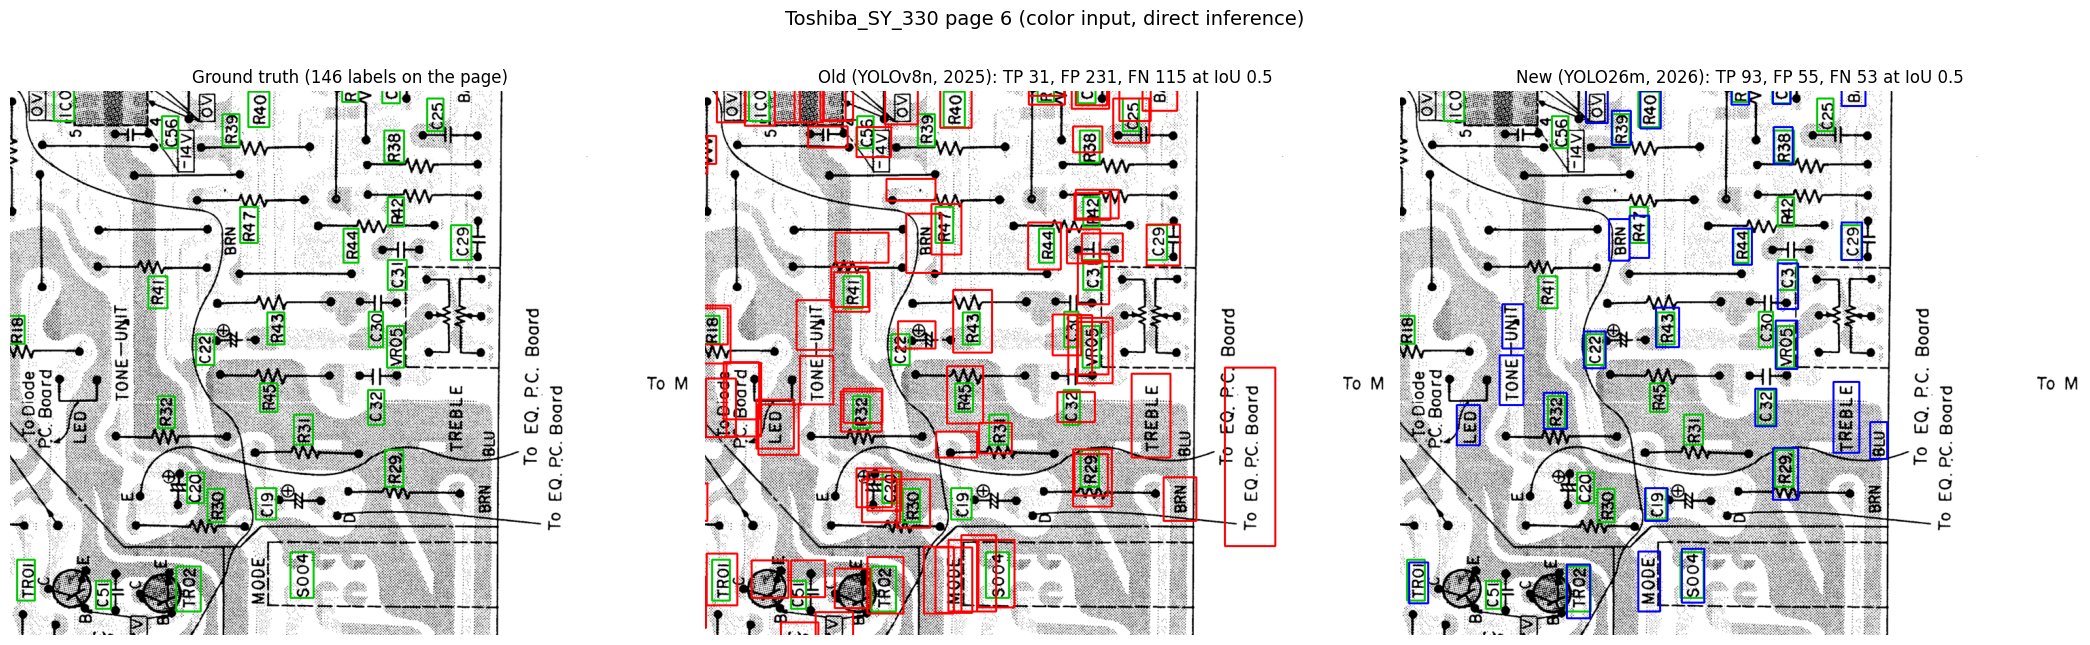

In [15]:
VIEWPORT_WIDTH = 1000
VIEWPORT_HEIGHT = 800
GT_COLOR = (0, 200, 0)
MODEL_COLORS = {"old": (0, 0, 255), "new": (255, 0, 0)}


def show_overlays(manual_id, page_num, input_mode, inference_mode):
    """ Plot ground truth and both models' predictions on a window of one page.

    Args:
      - manual_id (str) : Manual identifier.
      - page_num (int) : 1-based page index.
      - input_mode (str) : color or gray.
      - inference_mode (str) : direct or sliced.
    Returns: None.
    """
    page = [p for p in page_index if p["manual_id"] == manual_id and p["page"] == page_num][0]
    image = prepare_input(cv2.imread(str(page["img_file"])), input_mode)
    h_img, w_img = image.shape[:2]
    gt_boxes = page["gt_boxes"]

    center_x = float(np.median([(b[0] + b[2]) / 2.0 for b in gt_boxes]))
    center_y = float(np.median([(b[1] + b[3]) / 2.0 for b in gt_boxes]))
    x1 = int(min(max(0, center_x - VIEWPORT_WIDTH / 2), max(0, w_img - VIEWPORT_WIDTH)))
    y1 = int(min(max(0, center_y - VIEWPORT_HEIGHT / 2), max(0, h_img - VIEWPORT_HEIGHT)))
    x2 = min(w_img, x1 + VIEWPORT_WIDTH)
    y2 = min(h_img, y1 + VIEWPORT_HEIGHT)

    panels = [("Ground truth (" + str(len(gt_boxes)) + " labels on the page)", [], GT_COLOR)]
    for spec in MODELS:
        boxes, scores = predictions[(manual_id, page_num, input_mode, spec["key"], inference_mode)]
        m = evaluate_detection_predictions(boxes, scores, gt_boxes, PRIMARY_IOU)
        title = spec["label"] + ": TP " + str(m["tp"]) + ", FP " + str(m["fp"]) + ", FN " + str(m["fn"]) + " at IoU " + str(PRIMARY_IOU)
        panels.append((title, boxes, MODEL_COLORS[spec["key"]]))

    fig, axes = plt.subplots(1, len(panels), figsize=(7 * len(panels), 7))
    for ax, (title, boxes, color) in zip(axes, panels):
        canvas = image.copy()
        for b in gt_boxes:
            cv2.rectangle(canvas, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), GT_COLOR, 2)
        for b in boxes:
            cv2.rectangle(canvas, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), color, 2)
        ax.imshow(cv2.cvtColor(canvas[y1:y2, x1:x2], cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=12)
        ax.axis("off")
    fig.suptitle(manual_id + " page " + str(page_num) + " (" + input_mode + " input, " + inference_mode + " inference)", fontsize=14)
    plt.tight_layout()
    plt.show()


show_overlays("Toshiba_SY_330", 6, "color", "direct")

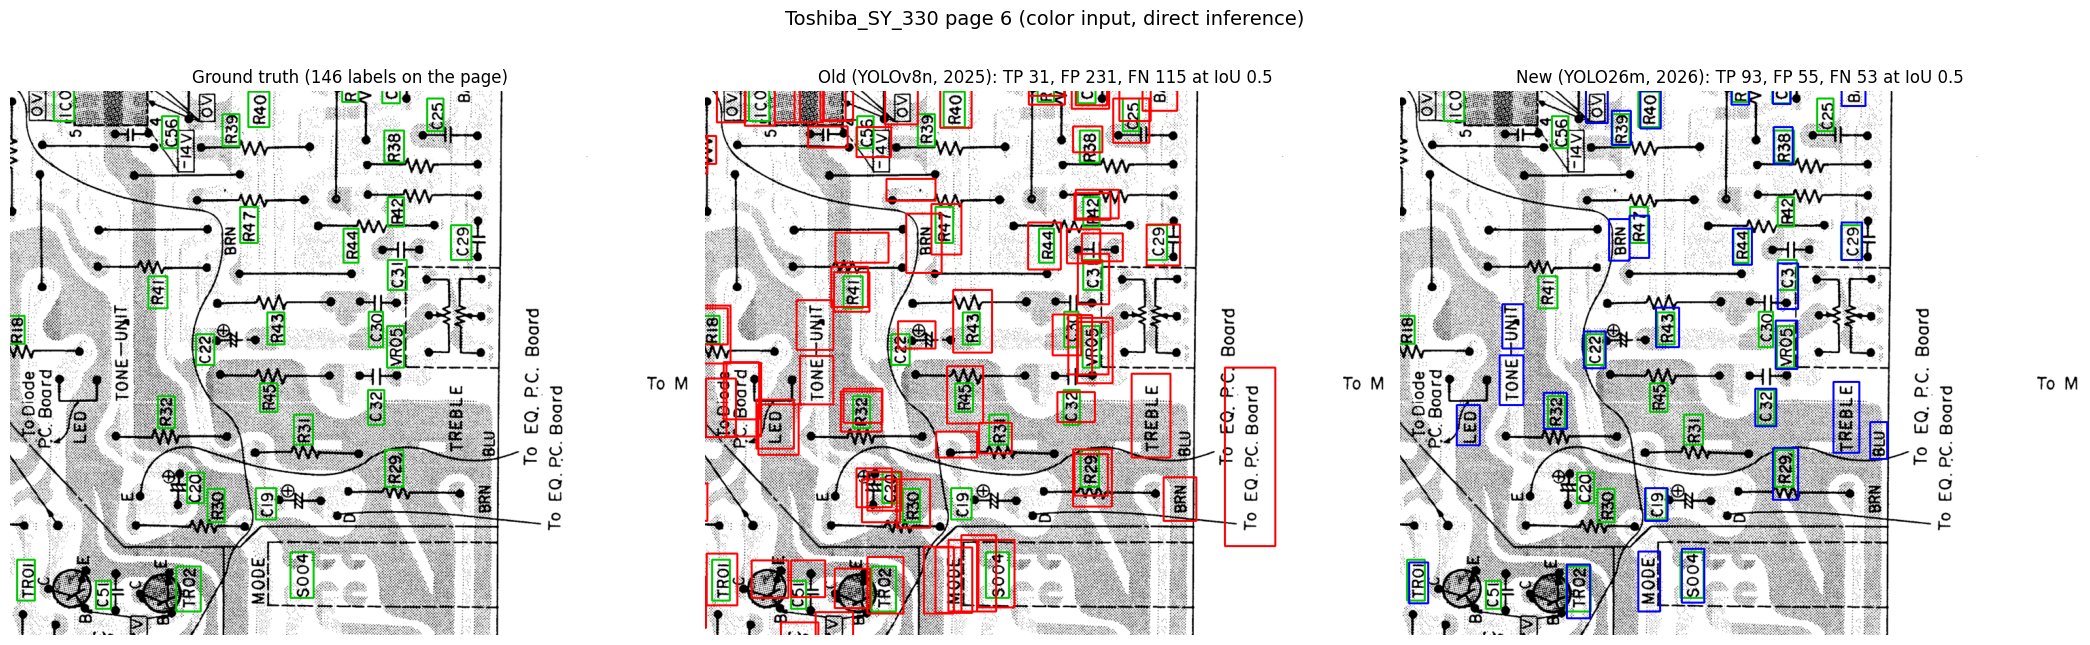

In [17]:
show_overlays("Toshiba_SY_330", 6, "color", "direct")

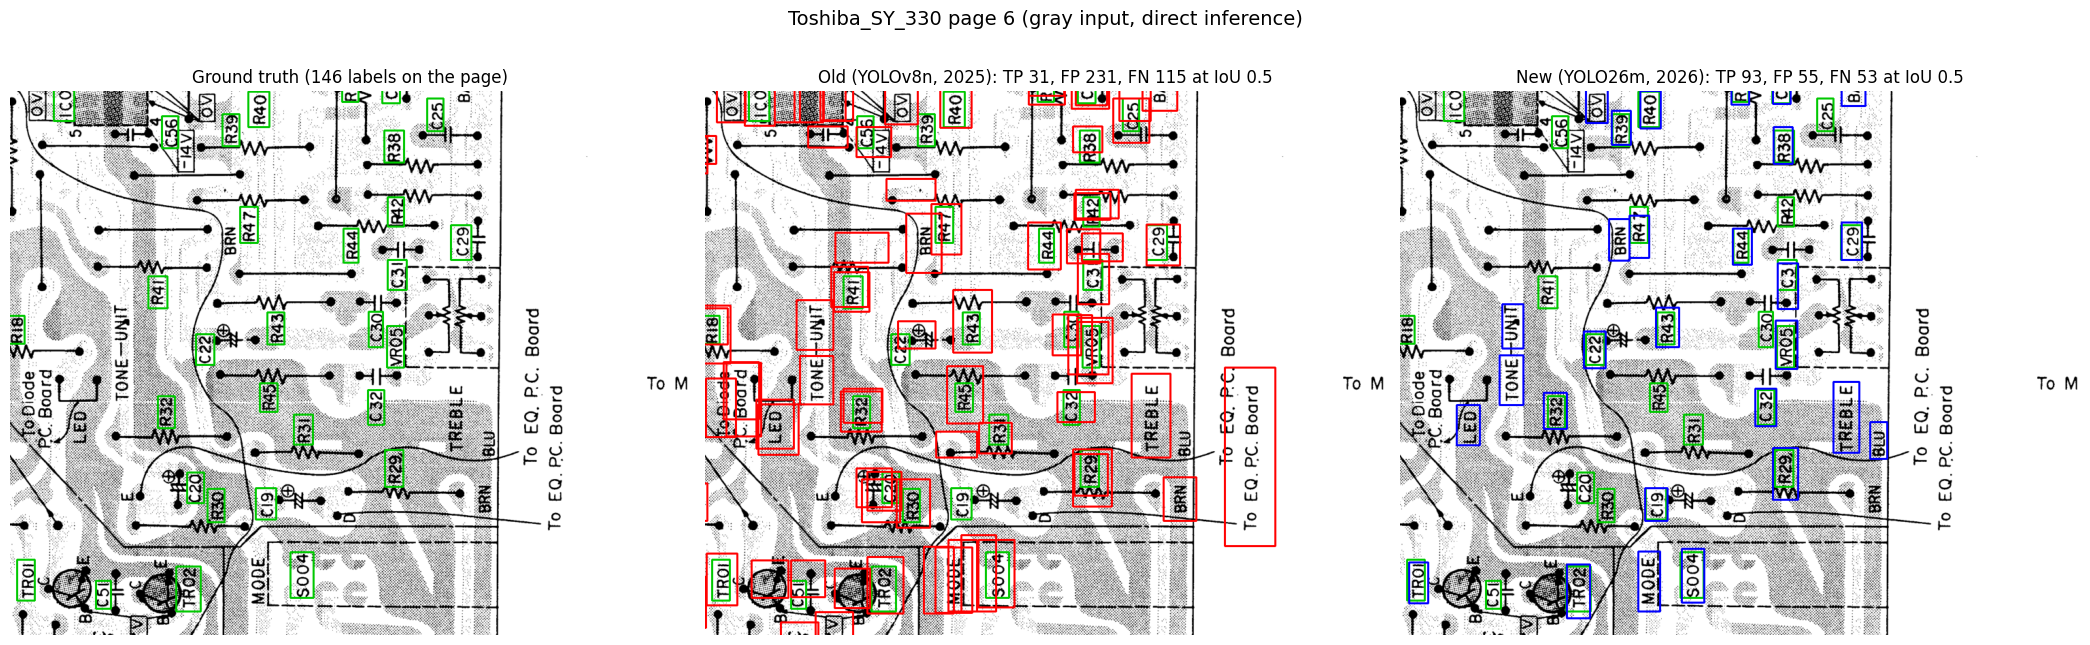

In [18]:
show_overlays("Toshiba_SY_330", 6, "gray", "direct")